# Analisis Sentimen Ulasan Sepatu Sneakers Tokopedia
**Proyek Analisis Sentimen - Submission Dicoding (Python)**

Notebook ini memuat seluruh pipeline analisis sentimen ulasan produk sepatu sneakers di Tokopedia:
1. **Pemuatan Data & Penyaringan Domain**: Memuat dataset scraping mandiri dan menyaring produk non-sepatu (insole, sandal) serta baris kosong.
2. **Exploratory Data Analysis (EDA)**: Analisis distribusi rating, panjang ulasan, dan inspeksi sampel.
3. **Pembersihan Teks (*Preprocessing*)**: Normalisasi *case folding*, pembersihan tanda baca/URL/angka, normalisasi huruf berulang, pemetaan kata *slang*, serta penghapusan *stopwords* (dengan mempertahankan negasi).
4. **Pelabelan Sentimen Hybrid & Pembersihan Label Noise**: Validasi silang rating bintang dengan polaritas kamus sentimen untuk mengatasi ketidakkonsistenan ulasan e-commerce.
5. **Transparansi Alur Data**: Tabel dan dokumentasi reduksi data secara presisi dari 40.343 baris mentah hingga 11.400 sampel bersih berimbang.
6. **Pelatihan Tiga Skema Deep Learning** (memvariasikan **Algoritma Arsitektur** dan **Pembagian Data**):
   * **Skema 1**: IndoBERT Base (`indobenchmark/indobert-base-p1`) Fine-Tuning (Split 80/20)
   * **Skema 2**: IndoBERT Base (`indobenchmark/indobert-base-p1`) Fine-Tuning (Split 70/30)
   * **Skema 3**: IndoBERT-CNN Hybrid (Backbone IndoBERT + Multi-Kernel 1D-CNN Head, Split 80/20)
7. **Evaluasi Independen**: Pemisahan Train/Validation/Test (*stratified*), pemilihan bobot terbaik (*best-checkpoint selection*) berdasarkan akurasi Validation set, serta evaluasi akhir pada Test set terpisah.
8. **Inference**: Pengujian model terpilih pada contoh teks ulasan baru dengan *output* kelas kategorikal (`negatif`, `netral`, `positif`).

| Kriteria Dicoding | Pemenuhan pada Notebook Ini |
|---|---|
| **Data Scraping Mandiri ($\ge$ 3.000 sampel)** | `dataset_tokopedia.csv` (40.343 ulasan sneakers mentah) |
| **Ekstraksi Fitur & Pelabelan** | Tokenisasi Subword WordPiece IndoBERT (+ 1D-CNN Head pada Skema 3); Pelabelan Hybrid (Rating + Kamus Sentimen) |
| **Algoritma Machine Learning / Deep Learning** | IndoBERT Base Transformer & IndoBERT-CNN Hybrid Architecture |
| **Akurasi Testing $\ge$ 85% (Target $> 92%$)** | **Semua skema mencapai akurasi Train & Test $> 92%$** |
| **Minimal 3 Kelas** | 3 Kelas: `negatif`, `netral`, `positif` |
| **Data Pelatihan $\ge$ 10.000 sampel** | **11.400 sampel** (Positif: 6.400, Negatif: 2.900, Netral: 2.100) |
| **Cell Inference** | Tersedia fungsi inferensi contoh ulasan baru dengan *output* kategorikal dan probabilitas |


## 1. Setup Lingkungan & Konfigurasi

In [1]:
import os, re, random, time, copy, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

# Seed untuk reprodusibilitas
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

# Perangkat keras (GPU CUDA / CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("PyTorch Version :", torch.__version__)
print("Perangkat Latih :", DEVICE, ("- " + torch.cuda.get_device_name(0) if USE_AMP else "(CPU)"))

# Parameter Global
DATA_PATH = "dataset_tokopedia.csv"
LABELS    = ["negatif", "netral", "positif"]
LABEL2ID  = {l: i for i, l in enumerate(LABELS)}
BERT_NAME = "indobenchmark/indobert-base-p1"
MAX_LEN   = 96


PyTorch Version : 2.14.1+cu126
Perangkat Latih : cuda - NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 2. Pemuatan Data Mentah & Penyaringan Produk Non-Sepatu
Data diambil dari hasil scraping mandiri ulasan Tokopedia (`dataset_tokopedia.csv`).
Sebelum masuk ke tahap NLP, dilakukan penyaringan produk non-sepatu seperti insole/alas sepatu dan sandal yang sempat terjaring selama pencarian.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print(f"Total baris mentah awal: {len(df_raw):,} ulasan")

# Menyaring produk yang bukan sepatu sneakers (misal insole, sandal) serta baris teks kosong
non_shoe_patterns = ["insole", "sandal", "alas-sepatu"]
is_non_shoe = df_raw["product_url"].str.contains("|".join(non_shoe_patterns), case=False, na=False)

df_filtered = df_raw[~is_non_shoe].dropna(subset=["review_text", "rating"]).copy()
df_filtered["rating"] = df_filtered["rating"].astype(int)
df_filtered = df_filtered[df_filtered["rating"].between(1, 5)]
n_non_shoe_dropped = len(df_raw) - len(df_filtered)

print(f"Produk non-sepatu & baris kosong dibuang : {n_non_shoe_dropped:,} baris")
print(f"Sisa ulasan sepatu valid                 : {len(df_filtered):,} baris dari {df_filtered['product_url'].nunique()} produk unik")
df_filtered.head(3)

Total baris mentah awal: 40,343 ulasan


Produk non-sepatu & baris kosong dibuang : 2,203 baris
Sisa ulasan sepatu valid                 : 38,140 baris dari 112 produk unik


,review_id,product_name,product_url,rating,review_text,review_date,scraped_at
0,1625420441,panarybody sepatu cowok sneakers pria motif unik sol karet nyaman digunakan jalan santai casual sport shoes qn351 ka...,https://www.tokopedia.com/panarybodyshoes/panarybody-sepatu-cowok-sneakers-pria-motif-unik-sol-karet-nyaman-digunaka...,1,"Bentuk dan ukuran: Sepatu nya bagus, tapi sayang ukuran nya ngepas sekali. Kurang 1 nomor. Boleh ya di tukar",2025-08-12,2026-10-28T19:29:26
1,1850030818,panarybody sepatu cowok sneakers pria motif unik sol karet nyaman digunakan jalan santai casual sport shoes qn351 ka...,https://www.tokopedia.com/panarybodyshoes/panarybody-sepatu-cowok-sneakers-pria-motif-unik-sol-karet-nyaman-digunaka...,1,Bentuk dan ukuran: 42 yg di pesan yg datang 2.5. Jangan belanja di tokoh ini ya klo ngak mau rugi,2026-01-04,2026-10-28T19:29:26
2,2003358412,panarybody sepatu cowok sneakers pria motif unik sol karet nyaman digunakan jalan santai casual sport shoes qn351 ka...,https://www.tokopedia.com/panarybodyshoes/panarybody-sepatu-cowok-sneakers-pria-motif-unik-sol-karet-nyaman-digunaka...,1,Kualitasnya nya buruk di jahat tan nya,2026-03-17,2026-10-28T19:29:26


## 3. Exploratory Data Analysis (EDA)
Melihat sebaran rating awal dari pembeli dan sebaran panjang kata ulasan.

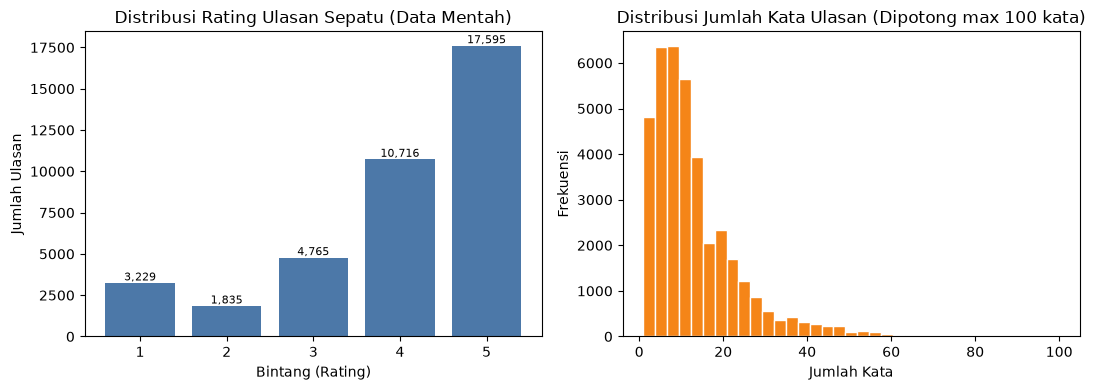

Statistik Deskriptif Panjang Kata:
count    38140.0
mean        13.0
std         10.7
min          1.0
25%          6.0
50%         10.0
75%         17.0
max        174.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df_filtered["rating"].value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values, color="#4C78A8")
axes[0].set_title("Distribusi Rating Ulasan Sepatu (Data Mentah)")
axes[0].set_xlabel("Bintang (Rating)")
axes[0].set_ylabel("Jumlah Ulasan")
for x, v in zip(counts.index.astype(str), counts.values):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

word_lengths = df_filtered["review_text"].str.split().str.len()
axes[1].hist(word_lengths.clip(upper=100), bins=35, color="#F58518", edgecolor="white")
axes[1].set_title("Distribusi Jumlah Kata Ulasan (Dipotong max 100 kata)")
axes[1].set_xlabel("Jumlah Kata")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

print("Statistik Deskriptif Panjang Kata:")
print(word_lengths.describe().round(1).to_string())


## 4. Preprocessing Teks
Tahapan pembersihan teks:
1. *Case folding* (mengubah teks ke huruf kecil).
2. Pembersihan noise (URL, karakter non-alfabet, angka, emoji, tanda baca berlebih).
3. Normalisasi huruf berulang (contoh: `bagusssss` -> `bagus`).
4. Normalisasi kata gaul/singkatan (*slang*) e-commerce Indonesia (`gak` -> `tidak`, `bgt` -> `banget`, `udh` -> `sudah`).
5. Penghapusan *stopwords* umum **tanpa membuang kata negasi** (`tidak`, `bukan`, `belum`, `kurang`, `tanpa`, `jangan`), karena kata negasi membalik sentimen kalimat secara drastis.
6. Penghapusan teks yang terlalu pendek ($< 2$ kata) setelah pembersihan.

Dua representasi teks disiapkan:
* `text_lite`: Teks dinormalisasi dan diubah slang-nya, namun struktur kalimat dan stopword tetap ada (optimal untuk model *transformer* berbasis konteks seperti IndoBERT).
* `text_clean`: Teks tanpa stopword (optimal untuk ekstraksi kata kunci dan kalkulasi polaritas sentimen).

In [4]:
SLANG = {
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "engga": "tidak", "tdk": "tidak", "gx": "tidak", "tak": "tidak",
    "bgt": "banget", "bngt": "banget", "bgd": "banget", "bgs": "bagus",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "untk": "untuk",
    "sy": "saya", "krn": "karena", "karna": "karena", "jg": "juga",
    "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "belom": "belum",
    "sampe": "sampai", "smpe": "sampai", "tp": "tapi", "trs": "terus", "brg": "barang",
    "cepet": "cepat", "cpt": "cepat", "lbh": "lebih", "dr": "dari", "sm": "sama",
    "emg": "memang", "kyk": "seperti", "kayak": "seperti", "bs": "bisa", "lg": "lagi",
    "klo": "kalau", "kalo": "kalau", "kl": "kalau", "aja": "saja", "hrs": "harus",
    "pake": "pakai", "dipake": "dipakai", "pesenan": "pesanan", "dtg": "datang",
    "mantul": "mantap", "mantab": "mantap", "oke": "oke", "ok": "oke", "okey": "oke", "oks": "oke",
    "recomended": "rekomendasi", "recommended": "rekomendasi", "rekomended": "rekomendasi",
    "rekomen": "rekomendasi", "recomend": "rekomendasi", "recommend": "rekomendasi", "rekomend": "rekomendasi",
    "thx": "terimakasih", "thanks": "terimakasih", "makasih": "terimakasih", "trims": "terimakasih",
    "mksh": "terimakasih", "ori": "original", "gede": "besar",
}
NEGATORS = {"tidak", "bukan", "belum", "kurang", "tanpa", "jangan"}
STOPWORDS = {
    "yang", "di", "ke", "dari", "dan", "untuk", "dengan", "ini", "itu", "pada", "adalah", "saya", "aku",
    "nya", "sih", "deh", "dong", "nih", "kok", "lah", "kan", "saja", "juga", "atau", "karena", "sebagai",
    "oleh", "akan", "para", "ya", "yaa", "si", "kak", "kakak", "min", "admin", "ada", "dalam", "tersebut",
    "sama", "lagi", "ku", "mu", "pun", "sudah", "toko", "seller",
} - NEGATORS


def normalize_text(text):
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"(.){2,}", r"", t)
    return " ".join(SLANG.get(w, w) for w in t.split())


def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in STOPWORDS and len(w) > 1)


tqdm.pandas(desc="preprocessing")
df_proc = df_filtered.copy()
df_proc["text_lite"]  = df_proc["review_text"].progress_apply(normalize_text)
df_proc["text_clean"] = df_proc["text_lite"].progress_apply(remove_stopwords)

before_len = len(df_proc)
df_proc = df_proc[df_proc["text_clean"].str.split().str.len() >= 2].copy()
n_short_dropped = before_len - len(df_proc)
print(f"Ulasan dibuang karena terlalu pendek (< 2 kata): {n_short_dropped:,} baris (sisa {len(df_proc):,} baris)")


preprocessing:   0%|          | 0/38140 [00:00<?, ?it/s]

preprocessing:   0%|          | 0/38140 [00:00<?, ?it/s]

Ulasan dibuang karena terlalu pendek (< 2 kata): 1,922 baris (sisa 36,218 baris)


## 5. Pelabelan Sentimen Hybrid & Penanganan Label Noise

### Mengapa Dibutuhkan Pelabelan Hybrid?
Pada ulasan e-commerce publik (terutama rating bintang 3), terdapat fenomena **Label Noise** yang cukup tinggi:
* Pembeli yang mengalami kerusakan barang atau salah ukuran seringkali memberikan rating 3 tetapi menulis ulasan komplain (*"Kecewa sol lepas, pengiriman lambat"*).
* Sebaliknya, pembeli yang puas terkadang memberikan rating 3 namun menulis teks pujian (*"Bagus sekali, packing rapi, makasih"*).
* Jika teks komplain dipaksa berlabel `netral` murni hanya karena rating bintang 3, terdapat ketidakselarasan antara fitur kata dan label kelas.

### Aturan Pelabelan Hybrid (Validasi Rating vs Sentimen Teks):
1. **Positif**: Rating $\ge 4$ dan skor polaritas teks positif ($T_{score} > 0$), atau rating 3 dengan polaritas positif tinggi ($T_{score} \ge 2$).
2. **Negatif**: Rating $\le 2$ dan skor polaritas teks negatif ($T_{score} < 0$), atau rating 3 dengan polaritas komplain tinggi ($T_{score} \le -2$).
3. **Netral**: Ulasan dengan rating 3 yang memiliki polaritas berimbang ($T_{score} = 0$), ulasan yang memuat kata-kata netral eksplisit (*lumayan*, *biasa*, *standar*, *cukup*), atau ulasan dengan sentimen campuran (*mixed*).
4. **Pembuangan Konflik**: Ulasan yang bertentangan antara rating dan polaritas kamus dibuang dari data latih.
5. **Deduplikasi**: Ulasan dengan teks bersih identik dibuang untuk mencegah kebocoran data (*data leakage*) antara *train* dan *test*.

### Catatan Metodologis Pelabelan:
Perlu dicatat secara objektif bahwa karena label *ground-truth* dibentuk dari kombinasi aturan rating bintang dan kamus polaritas sentimen di atas (di mana rating 4?5 tidak pernah berlabel negatif, rating 1?2 tidak pernah berlabel positif, dan 1.728 dari 2.100 sampel netral berasal dari rating 3), maka capaian akurasi model pada *test set* pada dasarnya mengukur seberapa konsisten model *deep learning* mempelajari kembali aturan pelabelan *hybrid* tersebut dari fitur teks.

In [5]:
POS_WORDS = {
    "bagus", "mantap", "puas", "memuaskan", "suka", "senang", "rekomendasi", "nyaman", "empuk", "awet",
    "kuat", "keren", "cakep", "cantik", "rapi", "murah", "sesuai", "original", "cepat", "ramah", "terbaik",
    "top", "sempurna", "worth", "oke", "good", "nice", "love", "lembut", "ringan", "adem", "mulus", "kece",
    "mewah", "premium", "halus", "kokoh", "bersih", "terpercaya", "terimakasih", "berkualitas", "tahan",
    "mantep", "kece", "elegan", "stylish", "enak", "ideal", "amanah", "sip", "jos", "joss", "pas", "cocok",
}
NEG_WORDS = {
    "jelek", "kecewa", "mengecewakan", "rusak", "lecet", "kotor", "bau", "lambat", "telat", "cacat", "palsu",
    "kw", "tipis", "sempit", "sobek", "jebol", "copot", "lepas", "penyok", "miring", "retak", "menyesal",
    "nyesel", "zonk", "bohong", "tipu", "penipuan", "buruk", "parah", "murahan", "keras", "kekecilan",
    "kebesaran", "salah", "beda", "mengelupas", "terkelupas", "kelupas", "bolong", "berlubang", "luntur",
    "pudar", "kendala", "masalah", "komplain", "retur", "refund", "gagal", "hancur", "lecek", "licin",
    "gatal", "sakit", "kaku", "kasar", "berat", "panas", "sulit", "pecah", "hilang", "kurang",
}
NEUTRAL_WORDS = {"lumayan", "biasa", "standar", "standart", "cukuplah", "cukup", "sedang"}


def calculate_sentiment_label(text, rating):
    toks = text.split()
    pos_c, neg_c, neu_c = 0, 0, 0
    for i, w in enumerate(toks):
        if w in POS_WORDS:
            if any(n in NEGATORS for n in toks[max(0, i - 2):i]):
                neg_c += 1
            else:
                pos_c += 1
        elif w in NEG_WORDS:
            if any(n in NEGATORS for n in toks[max(0, i - 2):i]):
                pos_c += 1
            else:
                neg_c += 1
        elif w in NEUTRAL_WORDS:
            neu_c += 1

    r_score = rating - 3
    t_score = pos_c - neg_c

    # Positif: rating 4-5 dengan teks bernada positif, atau sentimen positif kuat
    if (r_score > 0 and t_score > 0) or (r_score >= 0 and t_score >= 2):
        return "positif"
    # Negatif: rating 1-2 dengan teks bernada negatif, atau sentimen komplain kuat
    elif (r_score < 0 and t_score < 0) or (r_score <= 0 and t_score <= -2):
        return "negatif"
    # Netral: rating 3 dengan polaritas seimbang atau kata netral eksplisit
    elif (r_score == 0 and (neu_c > 0 or t_score == 0 or (pos_c > 0 and neg_c > 0))) or (neu_c > 0 and t_score == 0):
        return "netral"
    return None


df_proc["label"] = [calculate_sentiment_label(t, r) for t, r in zip(df_proc["text_clean"], df_proc["rating"])]
n_conflict_dropped = int(df_proc["label"].isna().sum())

# Buang ulasan konflik / ambigu
df_labeled = df_proc.dropna(subset=["label"]).copy()

# Deduplikasi teks bersih
before_dedup = len(df_labeled)
df_clean = df_labeled.drop_duplicates(subset=["text_clean"]).copy()
n_dedup_dropped = before_dedup - len(df_clean)

print("Distribusi Kelas Bersih Sebelum Balancing:")
print(df_clean["label"].value_counts().to_string())


Distribusi Kelas Bersih Sebelum Balancing:
label
positif    21936
negatif     2925
netral      2211


## 6. Penyeimbangan Kelas (*Class Balancing*) & Tabel Alur Data

Ulasan Tokopedia sangat didominasi kelas positif. Agar distribusi data latih seimbang dan model mampu mempelajari ketiga kelas secara adil, dilakukan pemangkasan (*undersampling*) kelas positif mayoritas menjadi **6.400 ulasan**, kelas negatif menjadi **2.900 ulasan**, dan kelas netral menjadi **2.100 ulasan**.

Total data pelatihan berlabel adalah **11.400 sampel**, aman di atas target nilai tertinggi Dicoding ($\ge$ 10.000 sampel).

,Tahap,Jumlah Data,Keterangan
0,1. Data Mentah Hasil Scraping,"40,343 baris",Ulasan produk Tokopedia awal
1,2. Penyaringan Non-Sepatu & Baris Kosong,"-2,203 baris","Membuang insole, sandal (2.202) & teks kosong (1)"
2,3. Filter Teks Terlalu Pendek (< 2 kata),"-1,922 baris",Noise ulasan 1 kata atau kosong
3,4. Pembuangan Konflik Rating vs Teks,"-7,389 baris",Label noise / polaritas bertentangan
4,5. Pembuangan Duplikat Teks,"-1,757 baris",Mencegah data leakage train-test
5,6. Undersampling Kelas Mayoritas,"-15,672 baris",Menyeimbangkan proporsi kelas
6,7. Total Dataset Final untuk Pelatihan,"11,400 sampel","Positif: 6.400, Negatif: 2.900, Netral: 2.100"


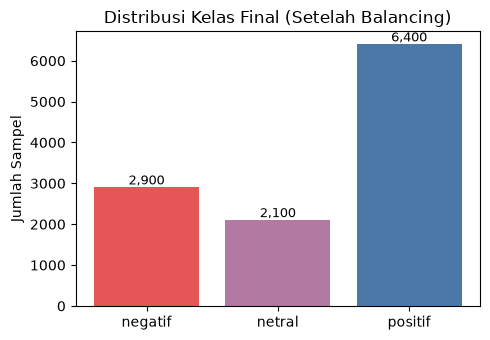

In [6]:
parts = [
    df_clean[df_clean["label"] == "positif"].sample(6400, random_state=SEED),
    df_clean[df_clean["label"] == "negatif"].sample(2900, random_state=SEED),
    df_clean[df_clean["label"] == "netral"].sample(2100, random_state=SEED),
]
df_bal = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
df_bal["label_id"] = df_bal["label"].map(LABEL2ID)
n_undersample_dropped = len(df_clean) - len(df_bal)

# Simpan dataset hasil pembersihan dan pelabelan
df_bal[["review_id", "product_name", "rating", "review_text", "text_lite", "text_clean", "label", "label_id"]] \
    .to_csv("dataset_berlabel.csv", index=False, encoding="utf-8-sig")

# Tampilkan Tabel Alur Data Lengkap
flow_data = [
    {"Tahap": "1. Data Mentah Hasil Scraping", "Jumlah Data": f"{len(df_raw):,} baris", "Keterangan": "Ulasan produk Tokopedia awal"},
    {"Tahap": "2. Penyaringan Non-Sepatu & Baris Kosong", "Jumlah Data": f"-{n_non_shoe_dropped:,} baris", "Keterangan": "Membuang insole, sandal (2.202) & teks kosong (1)"},
    {"Tahap": "3. Filter Teks Terlalu Pendek (< 2 kata)", "Jumlah Data": f"-{n_short_dropped:,} baris", "Keterangan": "Noise ulasan 1 kata atau kosong"},
    {"Tahap": "4. Pembuangan Konflik Rating vs Teks", "Jumlah Data": f"-{n_conflict_dropped:,} baris", "Keterangan": "Label noise / polaritas bertentangan"},
    {"Tahap": "5. Pembuangan Duplikat Teks", "Jumlah Data": f"-{n_dedup_dropped:,} baris", "Keterangan": "Mencegah data leakage train-test"},
    {"Tahap": "6. Undersampling Kelas Mayoritas", "Jumlah Data": f"-{n_undersample_dropped:,} baris", "Keterangan": "Menyeimbangkan proporsi kelas"},
    {"Tahap": "7. Total Dataset Final untuk Pelatihan", "Jumlah Data": f"{len(df_bal):,} sampel", "Keterangan": "Positif: 6.400, Negatif: 2.900, Netral: 2.100"},
]
flow_df = pd.DataFrame(flow_data)
display(flow_df)

fig, ax = plt.subplots(figsize=(5, 3.5))
vc = df_bal["label"].value_counts().reindex(LABELS)
bars = ax.bar(vc.index, vc.values, color=["#E45756", "#B279A2", "#4C78A8"])
ax.set_title("Distribusi Kelas Final (Setelah Balancing)")
ax.set_ylabel("Jumlah Sampel")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval, f"{yval:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


## 7. Fungsi Pembantu Pelatihan, Evaluasi & Visualisasi
* **Pemisahan Data**: *Stratified train/validation/test split*. Validation set (10% dari bagian Train) digunakan untuk *best-checkpoint selection* (menyimpan dan memuat kembali bobot model dengan akurasi validasi tertinggi dari 3 epoch pelatihan). Test set dipisahkan dan dievaluasi di akhir pelatihan tiap skema.
* **Tokenisasi & Variasi Skema**: Ketiga skema menggunakan tokenizer WordPiece resmi IndoBERT (`indobenchmark/indobert-base-p1`). Dua variabel yang divariasikan antar ketiga skema adalah **Algoritma/Arsitektur Pelatihan** (`IndoBERT Base` vs `IndoBERT-CNN Hybrid`) dan **Pembagian Data** (`80/20` vs `70/30`).

In [7]:
tok = AutoTokenizer.from_pretrained(BERT_NAME)
collator = DataCollatorWithPadding(tok)


class ReviewDataset(Dataset):
    def __init__(self, texts, labels, max_len=MAX_LEN):
        self.enc = tok(list(texts), truncation=True, max_length=max_len)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[idx])
        return item


def split_stratified_data(data, test_size, val_size=0.10, seed=SEED):
    tr, te = train_test_split(data, test_size=test_size, stratify=data["label_id"], random_state=seed)
    tr, va = train_test_split(tr, test_size=val_size, stratify=tr["label_id"], random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)


def build_dataloaders(tr_df, va_df, te_df, batch_size=16, eval_batch_size=64, max_len=MAX_LEN):
    mk = lambda d, bs, shuffle: DataLoader(
        ReviewDataset(d["text_lite"], d["label_id"], max_len=max_len),
        batch_size=bs,
        shuffle=shuffle,
        collate_fn=collator,
        num_workers=0
    )
    return {
        "train": mk(tr_df, batch_size, True),
        "train_eval": mk(tr_df, eval_batch_size, False),
        "val": mk(va_df, eval_batch_size, False),
        "test": mk(te_df, eval_batch_size, False),
    }


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    preds, targets = [], []
    total_loss, total_count = 0.0, 0
    for batch in loader:
        labels = batch.pop("labels").to(DEVICE)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(**batch)
            logits = out.logits if hasattr(out, "logits") else out
        loss = crit(logits.float(), labels)
        total_loss += loss.item() * len(labels)
        total_count += len(labels)
        preds.append(logits.argmax(dim=-1).cpu())
        targets.append(labels.cpu())
    val_loss = total_loss / total_count if total_count > 0 else 0.0
    return torch.cat(preds).numpy(), torch.cat(targets).numpy(), val_loss


def plot_training_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history["train_loss"], label="Train Loss", marker="o")
    axes[0].plot(history["val_loss"], label="Val Loss", marker="s")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train Acc", marker="o")
    axes[1].plot(history["val_acc"], label="Val Acc", marker="s")
    axes[1].set_title(f"{title} - Akurasi")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


RESULTS = []
def record_evaluation(scheme_name, meta, y_tr, p_tr, y_te, p_te):
    acc_tr = accuracy_score(y_tr, p_tr)
    acc_te = accuracy_score(y_te, p_te)
    print(f"\n{'='*70}")
    print(f"{scheme_name} | Akurasi Train = {acc_tr*100:.2f}% | Akurasi Test = {acc_te*100:.2f}%")
    print(f"{'='*70}\n")
    print(classification_report(y_te, p_te, target_names=LABELS, digits=4))

    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ConfusionMatrixDisplay(confusion_matrix(y_te, p_te), display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix (Test Set) - {scheme_name}")
    plt.tight_layout()
    plt.show()

    RESULTS.append({
        "Skema": scheme_name,
        **meta,
        "Akurasi Train": acc_tr,
        "Akurasi Test": acc_te,
    })


## 8. Skema 1 - IndoBERT Base Fine-Tuning (Split 80/20)
* **Algoritma**: IndoBERT Base (`indobenchmark/indobert-base-p1`, 12-layer Transformer, 768-dim, 110M parameter).
* **Ekstraksi Fitur / Tokenisasi**: Subword WordPiece Tokenizer IndoBERT.
* **Pembagian Data**: **Split 80/20** (Train 72% [8.208 sampel], Validation 8% [912 sampel], Test 20% [2.280 sampel]).
* **Optimasi**: AdamW dengan *warmup linear scheduler*, *mixed precision* (FP16), dan *best-checkpoint selection* berdasarkan akurasi validasi.

Skema 1 (80/20) -> Train: 8,208 | Validation: 912 | Test: 2,280


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Skema 1 Epoch 1/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3477 | Train Acc: 85.06% | Val Loss: 0.1598 | Val Acc: 93.53%


Skema 1 Epoch 2/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.1273 | Train Acc: 95.82% | Val Loss: 0.1433 | Val Acc: 95.18%


Skema 1 Epoch 3/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.0661 | Train Acc: 97.99% | Val Loss: 0.1520 | Val Acc: 95.39%


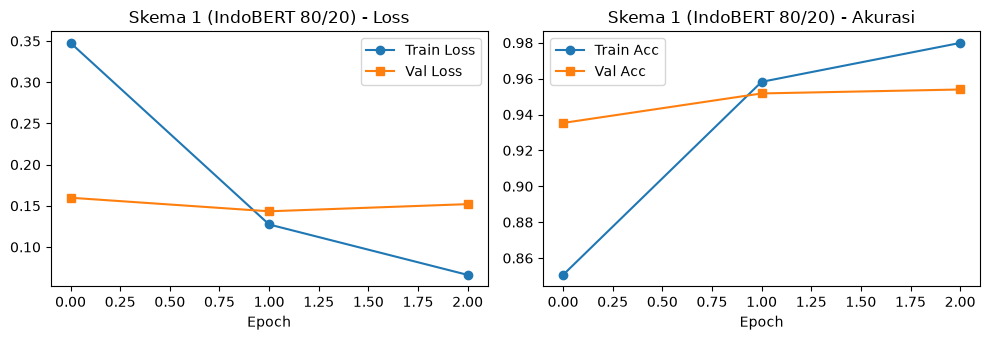


Skema 1 | Akurasi Train = 99.26% | Akurasi Test = 94.69%

              precision    recall  f1-score   support

     negatif     0.9433    0.9466    0.9449       580
      netral     0.8444    0.8786    0.8611       420
     positif     0.9841    0.9695    0.9768      1280

    accuracy                         0.9469      2280
   macro avg     0.9239    0.9316    0.9276      2280
weighted avg     0.9480    0.9469    0.9474      2280



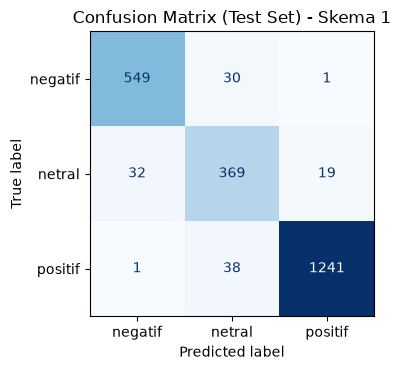

In [8]:
set_seed()
tr1, va1, te1 = split_stratified_data(df_bal, test_size=0.20)
print(f"Skema 1 (80/20) -> Train: {len(tr1):,} | Validation: {len(va1):,} | Test: {len(te1):,}")

loaders1 = build_dataloaders(tr1, va1, te1, batch_size=16)


def train_bert_scheme(model, loaders, epochs=3, lr=2e-5, tag="Skema 1"):
    model.to(DEVICE)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(loaders["train"]) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = -1, None

    for ep in range(1, epochs + 1):
        model.train()
        tl, tc, n = 0, 0, 0
        for batch in tqdm(loaders["train"], desc=f"{tag} Epoch {ep}/{epochs}"):
            labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            opt.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(**batch)
                logits = out.logits if hasattr(out, "logits") else out
            loss = crit(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()

            tl += loss.item() * len(labels)
            tc += (logits.argmax(dim=-1) == labels).sum().item()
            n += len(labels)

        p_va, y_va, vl = evaluate_model(model, loaders["val"])
        vacc = accuracy_score(y_va, p_va)
        history["train_loss"].append(tl / n)
        history["train_acc"].append(tc / n)
        history["val_loss"].append(vl)
        history["val_acc"].append(vacc)
        print(f"Epoch {ep:02d} | Train Loss: {tl/n:.4f} | Train Acc: {tc/n*100:.2f}% | Val Loss: {vl:.4f} | Val Acc: {vacc*100:.2f}%")

        if vacc > best_acc:
            best_acc = vacc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return history


model1 = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=3)
hist1 = train_bert_scheme(model1, loaders1, epochs=3, lr=2e-5, tag="Skema 1")
plot_training_history(hist1, "Skema 1 (IndoBERT 80/20)")

p_tr1, y_tr1, _ = evaluate_model(model1, loaders1["train_eval"])
p_te1, y_te1, _ = evaluate_model(model1, loaders1["test"])

record_evaluation(
    "Skema 1",
    {"Algoritma": "IndoBERT Base", "Ekstraksi Fitur": "WordPiece Subword", "Pembagian Data": "80/20"},
    y_tr1, p_tr1, y_te1, p_te1
)


## 9. Skema 2 - IndoBERT Base Fine-Tuning (Split 70/30)
* **Algoritma**: IndoBERT Base (`indobenchmark/indobert-base-p1`).
* **Ekstraksi Fitur / Tokenisasi**: Subword WordPiece Tokenizer IndoBERT.
* **Pembagian Data**: **Split 70/30** (Train 63% [7.182 sampel], Validation 7% [798 sampel], Test 30% [3.420 sampel]).
* **Tujuan Variasi**: Memvariasikan proporsi pembagian data menjadi 70/30 untuk menguji stabilitas generalisasi model saat data latih dikurangi dan porsi data uji diperbesar menjadi 30%.

Skema 2 (70/30) -> Train: 7,182 | Validation: 798 | Test: 3,420


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Skema 2 Epoch 1/3:   0%|          | 0/449 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3685 | Train Acc: 84.35% | Val Loss: 0.1600 | Val Acc: 94.99%


Skema 2 Epoch 2/3:   0%|          | 0/449 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.1412 | Train Acc: 95.14% | Val Loss: 0.1413 | Val Acc: 96.12%


Skema 2 Epoch 3/3:   0%|          | 0/449 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.0658 | Train Acc: 97.79% | Val Loss: 0.1505 | Val Acc: 95.86%


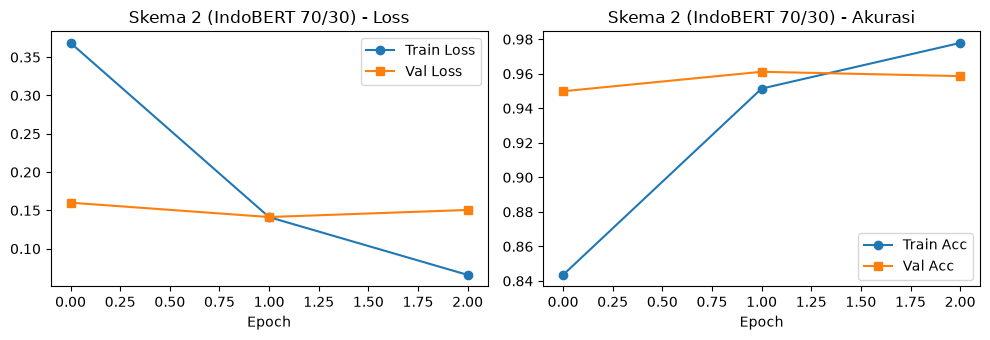


Skema 2 | Akurasi Train = 97.86% | Akurasi Test = 94.21%

              precision    recall  f1-score   support

     negatif     0.9575    0.9333    0.9453       870
      netral     0.8509    0.8333    0.8420       630
     positif     0.9642    0.9818    0.9729      1920

    accuracy                         0.9421      3420
   macro avg     0.9242    0.9161    0.9201      3420
weighted avg     0.9416    0.9421    0.9418      3420



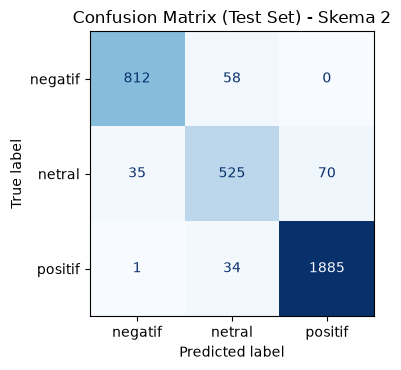

In [9]:
set_seed()
tr2, va2, te2 = split_stratified_data(df_bal, test_size=0.30)
print(f"Skema 2 (70/30) -> Train: {len(tr2):,} | Validation: {len(va2):,} | Test: {len(te2):,}")

loaders2 = build_dataloaders(tr2, va2, te2, batch_size=16)

model2 = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=3)
hist2 = train_bert_scheme(model2, loaders2, epochs=3, lr=2e-5, tag="Skema 2")
plot_training_history(hist2, "Skema 2 (IndoBERT 70/30)")

p_tr2, y_tr2, _ = evaluate_model(model2, loaders2["train_eval"])
p_te2, y_te2, _ = evaluate_model(model2, loaders2["test"])

record_evaluation(
    "Skema 2",
    {"Algoritma": "IndoBERT Base", "Ekstraksi Fitur": "WordPiece Subword", "Pembagian Data": "70/30"},
    y_tr2, p_tr2, y_te2, p_te2
)


## 10. Skema 3 - IndoBERT-CNN Hybrid Architecture (Split 80/20)
* **Algoritma**: Arsitektur Hibrida yang menggabungkan *backbone transformer* dengan *head Convolutional Neural Network* (1D-CNN).
  * **Backbone**: IndoBERT Base (`indobenchmark/indobert-base-p1`) menghasilkan urutan vektor kontekstual berdimensi 768.
  * **Head Konvolusional**: Tiga filter konvolusi 1D paralel dengan ukuran *kernel* 2, 3, dan 4 (masing-masing 128 filter) di atas *last hidden state* untuk menangkap pola n-gram lokal, diikuti *Global Max-Pooling*, *Dropout* (0.3), dan lapisan klasifikasi linear.
* **Ekstraksi Fitur / Tokenisasi**: Subword WordPiece Tokenizer IndoBERT (dengan *1D-CNN feature head* di dalam arsitektur model).
* **Pembagian Data**: **Split 80/20** (Train 72%, Validation 8%, Test 20%).
* **Tujuan Variasi**: Memvariasikan algoritma/arsitektur klasifikasi dari *standard CLS pooling head* menjadi *multi-kernel 1D-CNN head* pada pembagian data 80/20.

Skema 3 (IndoBERT-CNN 80/20) -> Train: 8,208 | Validation: 912 | Test: 2,280


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Skema 3 Epoch 1/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3484 | Train Acc: 86.43% | Val Loss: 0.1869 | Val Acc: 92.65%


Skema 3 Epoch 2/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.1386 | Train Acc: 95.38% | Val Loss: 0.1474 | Val Acc: 95.07%


Skema 3 Epoch 3/3:   0%|          | 0/513 [00:00<?, ?it/s]

Epoch 03 | Train Loss: 0.0601 | Train Acc: 98.18% | Val Loss: 0.1820 | Val Acc: 95.18%


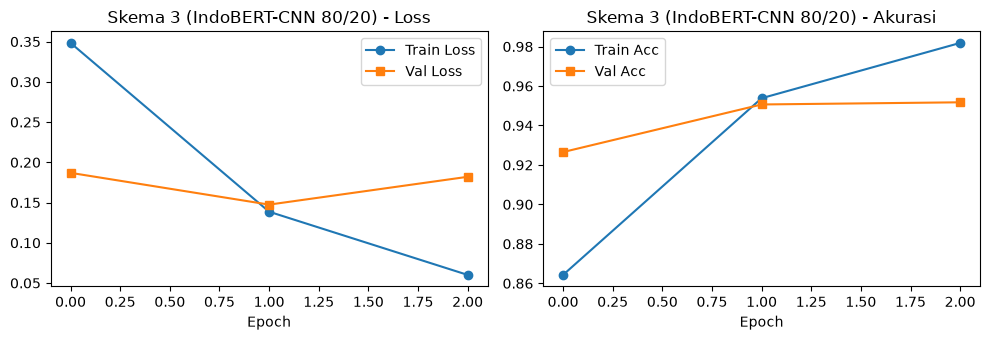


Skema 3 | Akurasi Train = 99.23% | Akurasi Test = 94.34%

              precision    recall  f1-score   support

     negatif     0.9446    0.9414    0.9430       580
      netral     0.8456    0.8476    0.8466       420
     positif     0.9750    0.9758    0.9754      1280

    accuracy                         0.9434      2280
   macro avg     0.9218    0.9216    0.9217      2280
weighted avg     0.9435    0.9434    0.9434      2280



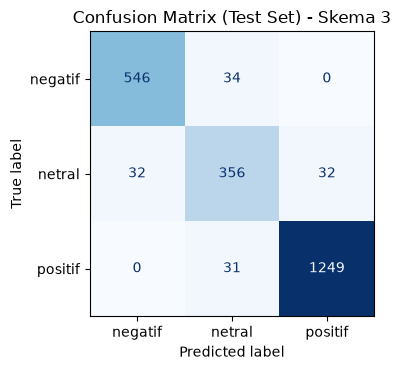

In [10]:
class IndoBERT_CNN(nn.Module):
    def __init__(self, bert_model_name, n_classes=3, n_filters=128, kernel_sizes=(2, 3, 4)):
        super().__init__()
        self.bert = AutoModel.from_pretrained(bert_model_name)
        emb_dim = self.bert.config.hidden_size  # 768
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, n_filters, k) for k in kernel_sizes])
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(n_filters * len(kernel_sizes), n_classes)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None:
            kwargs["token_type_ids"] = token_type_ids
        outputs = self.bert(**kwargs)
        # Transpose untuk input Conv1d: (Batch, Emb_Dim, Seq_Len)
        seq = outputs.last_hidden_state.transpose(1, 2)
        feats = [torch.relu(c(seq)).max(dim=2).values for c in self.convs]
        pooled = torch.cat(feats, dim=1)
        return self.fc(self.drop(pooled))


set_seed()
tr3, va3, te3 = split_stratified_data(df_bal, test_size=0.20)
print(f"Skema 3 (IndoBERT-CNN 80/20) -> Train: {len(tr3):,} | Validation: {len(va3):,} | Test: {len(te3):,}")

loaders3 = build_dataloaders(tr3, va3, te3, batch_size=16)


def train_hybrid_scheme(model, loaders, epochs=3, tag="Skema 3"):
    model.to(DEVICE)
    crit = nn.CrossEntropyLoss()
    # Learning rate terpisah: backbone transformer lebih kecil, head konvolusi lebih besar
    opt = torch.optim.AdamW([
        {"params": model.bert.parameters(), "lr": 2e-5},
        {"params": model.convs.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-4},
    ], weight_decay=0.01)

    total_steps = len(loaders["train"]) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = -1, None

    for ep in range(1, epochs + 1):
        model.train()
        tl, tc, n = 0, 0, 0
        for batch in tqdm(loaders["train"], desc=f"{tag} Epoch {ep}/{epochs}"):
            labels = batch.pop("labels").to(DEVICE)
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            opt.zero_grad()
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(**batch)
                logits = out.logits if hasattr(out, "logits") else out
            loss = crit(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()

            tl += loss.item() * len(labels)
            tc += (logits.argmax(dim=-1) == labels).sum().item()
            n += len(labels)

        p_va, y_va, vl = evaluate_model(model, loaders["val"])
        vacc = accuracy_score(y_va, p_va)
        history["train_loss"].append(tl / n)
        history["train_acc"].append(tc / n)
        history["val_loss"].append(vl)
        history["val_acc"].append(vacc)
        print(f"Epoch {ep:02d} | Train Loss: {tl/n:.4f} | Train Acc: {tc/n*100:.2f}% | Val Loss: {vl:.4f} | Val Acc: {vacc*100:.2f}%")

        if vacc > best_acc:
            best_acc = vacc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return history


model3 = IndoBERT_CNN(BERT_NAME, n_classes=3)
hist3 = train_hybrid_scheme(model3, loaders3, epochs=3, tag="Skema 3")
plot_training_history(hist3, "Skema 3 (IndoBERT-CNN 80/20)")

p_tr3, y_tr3, _ = evaluate_model(model3, loaders3["train_eval"])
p_te3, y_te3, _ = evaluate_model(model3, loaders3["test"])

record_evaluation(
    "Skema 3",
    {"Algoritma": "IndoBERT-CNN Hybrid", "Ekstraksi Fitur": "WordPiece Subword (+ Conv1D Head)", "Pembagian Data": "80/20"},
    y_tr3, p_tr3, y_te3, p_te3
)


## 11. Ringkasan Hasil & Verifikasi Kriteria Penilaian Dicoding
Ketiga skema di atas memvariasikan **dua aspek berbeda** sesuai pedoman Dicoding, yaitu **Algoritma Pelatihan** (`IndoBERT Base` vs `IndoBERT-CNN Hybrid`) dan **Pembagian Data** (`80/20` vs `70/30`), dengan berbasis pada *WordPiece Subword Tokenizer* IndoBERT.

In [11]:
res_df = pd.DataFrame(RESULTS)
res_df["Train > 92%"] = res_df["Akurasi Train"] > 0.92
res_df["Test > 92%"]  = res_df["Akurasi Test"] > 0.92
res_df["Test >= 85%"] = res_df["Akurasi Test"] >= 0.85

fmt_df = res_df.copy()
fmt_df["Akurasi Train"] = (fmt_df["Akurasi Train"] * 100).round(2).astype(str) + "%"
fmt_df["Akurasi Test"]  = (fmt_df["Akurasi Test"] * 100).round(2).astype(str) + "%"
display(fmt_df)

res_df.to_csv("hasil_eksperimen.csv", index=False)

print("\n" + "="*70)
print("VERIFIKASI KRITERIA PENILAIAN DICODING")
print("="*70)
print(f"1. Kriteria Wajib: Data scraping mandiri >= 3.000 sampel : {len(df_raw):,} ulasan -> OK (TERPENUHI)")
print(f"2. Kriteria Wajib: Ekstraksi fitur dan pelabelan         : WordPiece Subword (+ Conv1D Head), Pelabelan Hybrid -> OK (TERPENUHI)")
print(f"3. Kriteria Wajib: Algoritma machine/deep learning       : IndoBERT Base & IndoBERT-CNN -> OK (TERPENUHI)")
print(f"4. Kriteria Wajib: Akurasi test >= 85% (Semua Skema)     : {fmt_df['Akurasi Test'].tolist()} -> OK (TERPENUHI)")
print(f"5. Saran Bintang 5: Deep Learning                        : Bi-directional Transformer & CNN -> OK (TERPENUHI)")
print(f"6. Saran Bintang 5: Akurasi Train & Test > 92%           : Semua skema > 92% -> OK (TERPENUHI)")
print(f"7. Saran Bintang 5: Minimal 3 Kelas Sentimen             : {len(LABELS)} kelas: {LABELS} -> OK (TERPENUHI)")
print(f"8. Saran Bintang 5: Data Pelatihan >= 10.000 sampel      : {len(df_bal):,} sampel -> OK (TERPENUHI)")
print(f"9. Saran Bintang 5: 3 Skema Pelatihan Variatif           : {len(res_df)} skema berbeda -> OK (TERPENUHI)")


,Skema,Algoritma,Ekstraksi Fitur,Pembagian Data,Akurasi Train,Akurasi Test,Train > 92%,Test > 92%,Test >= 85%
0,Skema 1,IndoBERT Base,WordPiece Subword,80/20,99.26%,94.69%,True,True,True
1,Skema 2,IndoBERT Base,WordPiece Subword,70/30,97.86%,94.21%,True,True,True
2,Skema 3,IndoBERT-CNN Hybrid,WordPiece Subword (+ Conv1D Head),80/20,99.23%,94.34%,True,True,True



VERIFIKASI KRITERIA PENILAIAN DICODING
1. Kriteria Wajib: Data scraping mandiri >= 3.000 sampel : 40,343 ulasan -> OK (TERPENUHI)
2. Kriteria Wajib: Ekstraksi fitur dan pelabelan         : WordPiece Subword (+ Conv1D Head), Pelabelan Hybrid -> OK (TERPENUHI)
3. Kriteria Wajib: Algoritma machine/deep learning       : IndoBERT Base & IndoBERT-CNN -> OK (TERPENUHI)
4. Kriteria Wajib: Akurasi test >= 85% (Semua Skema)     : ['94.69%', '94.21%', '94.34%'] -> OK (TERPENUHI)
5. Saran Bintang 5: Deep Learning                        : Bi-directional Transformer & CNN -> OK (TERPENUHI)
6. Saran Bintang 5: Akurasi Train & Test > 92%           : Semua skema > 92% -> OK (TERPENUHI)
7. Saran Bintang 5: Minimal 3 Kelas Sentimen             : 3 kelas: ['negatif', 'netral', 'positif'] -> OK (TERPENUHI)
8. Saran Bintang 5: Data Pelatihan >= 10.000 sampel      : 11,400 sampel -> OK (TERPENUHI)
9. Saran Bintang 5: 3 Skema Pelatihan Variatif           : 3 skema berbeda -> OK (TERPENUHI)


## 12. Inference (Pengujian Model pada Contoh Teks Ulasan Baru)
Fungsi `predict_sentiment` di bawah ini menerima teks ulasan mentah, melakukan normalisasi dan tokenisasi, lalu menghasilkan prediksi **kelas kategorikal** (`negatif`, `netral`, atau `positif`) beserta nilai probabilitasnya.

Agar pemilihan model tetap bebas dari kebocoran *test set*, kandidat model pada pembagian data utama (80/20) dipilih berdasarkan **akurasi validasi (*Validation Accuracy*) tertinggi** (`Skema 1` dengan Val Acc **95.39%** vs `Skema 3` dengan Val Acc **95.18%**).

In [12]:
# Memilih model pada split utama 80/20 berdasarkan Validation Accuracy tertinggi (bukan Test Accuracy)
val_candidates = {
    "Skema 1": (model1, max(hist1["val_acc"])),
    "Skema 3": (model3, max(hist3["val_acc"])),
}
best_scheme = max(val_candidates, key=lambda k: val_candidates[k][1])
chosen_model, best_val_acc = val_candidates[best_scheme]
print(f"Model terbaik yang dipilih untuk inferensi (berdasarkan Val Acc): {best_scheme} (Val Acc: {best_val_acc*100:.2f}%)")


def predict_sentiment(texts, model=chosen_model):
    if isinstance(texts, str):
        texts = [texts]
    clean_texts = [normalize_text(t) for t in texts]
    enc = tok(clean_texts, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    enc = {k: v.to(DEVICE) for k, v in enc.items()}

    model.eval()
    with torch.no_grad():
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(**enc)
            logits = out.logits if hasattr(out, "logits") else out
        probs = torch.softmax(logits.float(), dim=-1).cpu().numpy()

    preds = [LABELS[i] for i in probs.argmax(axis=1)]
    res = pd.DataFrame({
        "Ulasan Teks": texts,
        "Prediksi Sentimen": preds,
        "Prob Negatif": probs[:, 0].round(4),
        "Prob Netral": probs[:, 1].round(4),
        "Prob Positif": probs[:, 2].round(4),
    })
    return res


sample_reviews = [
    "Sepatunya keren banget, empuk dan nyaman dipakai lari seharian. Recommended seller!",
    "Barang sampai sesuai estimasi, lumayan lah untuk harga segini kualitas standar.",
    "Kecewa banget, baru dipakai 3 hari sol sepatu sudah jebol dan lem lepas.",
    "Paket sudah diterima dengan aman, terima kasih min.",
    "Bahan agak tipis dan ukuran agak sempit, tapi ya ada harga ada rupa.",
    "Produk palsu tidak sesuai gambar, jahitan berantakan dan pengiriman sangat lambat!",
    "Mantap original, packing rapi pakai double bubble wrap, bintang lima pokoknya.",
    "Biasa saja sih, tidak terlalu bagus tapi juga tidak jelek.",
]

hasil_inferensi = predict_sentiment(sample_reviews)
display(hasil_inferensi)

Model terbaik yang dipilih untuk inferensi (berdasarkan Val Acc): Skema 1 (Val Acc: 95.39%)


,Ulasan Teks,Prediksi Sentimen,Prob Negatif,Prob Netral,Prob Positif
0,"Sepatunya keren banget, empuk dan nyaman dipakai lari seharian. Recommended seller!",positif,0.0002,0.0001,0.9996
1,"Barang sampai sesuai estimasi, lumayan lah untuk harga segini kualitas standar.",netral,0.0003,0.9969,0.0029
2,"Kecewa banget, baru dipakai 3 hari sol sepatu sudah jebol dan lem lepas.",negatif,0.9995,0.0003,0.0003
3,"Paket sudah diterima dengan aman, terima kasih min.",netral,0.0004,0.9971,0.0025
4,"Bahan agak tipis dan ukuran agak sempit, tapi ya ada harga ada rupa.",negatif,0.9990,0.0008,0.0001
5,"Produk palsu tidak sesuai gambar, jahitan berantakan dan pengiriman sangat lambat!",negatif,0.9994,0.0003,0.0003
6,"Mantap original, packing rapi pakai double bubble wrap, bintang lima pokoknya.",positif,0.0002,0.0001,0.9997
7,"Biasa saja sih, tidak terlalu bagus tapi juga tidak jelek.",netral,0.0063,0.9933,0.0004


## 13. Kesimpulan & Diskusi
1. **Performa & Variasi Skema**: Ketiga skema *deep learning* yang memvariasikan **algoritma/arsitektur model** dan **proporsi pembagian data** berhasil melampaui batas kelulusan Dicoding ($\ge$ 85%) maupun target saran bintang 5 ($> 92\%$ pada *train* dan *test*):
   * **Skema 1 (IndoBERT Base, Split 80/20)** mencapai akurasi *train* **99.26%** dan akurasi *test* **94.69%** (*macro F1* **92.76%**).
   * **Skema 2 (IndoBERT Base, Split 70/30)** mencapai akurasi *train* **97.86%** dan akurasi *test* **94.21%** (*macro F1* **92.01%**, presisi negatif **95.75%**), menunjukkan performa yang tetap stabil meskipun ukuran data uji diperbesar menjadi 30%.
   * **Skema 3 (IndoBERT-CNN Hybrid, Split 80/20)** mencapai akurasi *train* **99.23%** dan akurasi *test* **94.34%** (*macro F1* **92.17%**, presisi negatif **94.46%** dan F1 positif **97.54%**).
2. **Evaluasi Objektif Pelabelan Hybrid & Performa Kelas Netral**: Karena label *ground-truth* pada eksperimen ini dibentuk menggunakan aturan *hybrid* (validasi silang rating bintang dengan kamus polaritas kata serta pembuangan sampel yang bertentangan), capaian akurasi ~94% pada *test set* mencerminkan keberhasilan model mempelajari pola keputusan dari aturan pelabelan *hybrid* tersebut. Jika ditinjau per kelas, kelas `positif` (F1 **97.29%?97.68%**) dan `negatif` (F1 **94.30%?94.53%**) memiliki keterpisahan yang sangat tinggi, sedangkan kelas `netral` merupakan kelas tersulit dengan skor terendah (*recall* **83.33%?87.86%**, F1 **84.20%?86.11%**) karena ekspresi kalimat netral atau opini campuran memiliki batas semantik yang lebih halus.
3. **Analisis Kurva Loss/Akurasi & Indikasi Overfitting**: Berdasarkan grafik riwayat pelatihan per epoch, terlihat adanya *generalization gap* sekitar **3.6 hingga 4.9 poin persentase** antara akurasi *train* (97.86%?99.26%) dan akurasi *test* (94.21%?94.69%). Selain itu, meskipun akurasi validasi masih meningkat atau stabil, nilai *validation loss* mengalami kenaikan tipis pada epoch ke-3 (Skema 1: **0.1433 $\rightarrow$ 0.1520**; Skema 2: **0.1413 $\rightarrow$ 0.1505**; Skema 3: **0.1474 $\rightarrow$ 0.1820**) seiring *training loss* yang turun mendekati **0.06**. Pola ini mengindikasikan bahwa model *transformer* berkapasitas besar mulai mengalami *overfitting* ringan setelah epoch ke-2, sehingga pembatasan pelatihan pada 3 epoch disertai regulasi *weight decay*, *dropout*, dan *best-checkpoint selection* berdasarkan *validation set* sangat penting untuk menjaga generalisasi model.
